In [2]:
# needed when using ssh connection (?)
%pip install tensorboard
%pip install numpy
%pip install torch
%pip install matplotlib
%pip install os

Defaulting to user installation because normal site-packages is not writeable


Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
ERROR: Could not find a version that satisfies the requirement os (from versions: none)
ERROR: No matching distribution found for os
Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import os
from torch.utils.data import DataLoader, TensorDataset, random_split
from torch.utils.tensorboard import SummaryWriter

In [ ]:
cwd = os.getcwd()

ssh_connected = 1 # change to 1 if connected to supercomputer

if ssh_connected == 0:
    num_csvs = len(os.listdir("C:\\Users\\seanf\\OneDrive\\Documents\\Master's Files\\2nd Year\\Eclipsing Binaries\\Data\\ELISa lightcurve data"))
elif ssh_connected ==1:
    num_csvs = len(os.listdir("/home/astrouser/sean/Eclipsing Binaries/Data/ELISa lightcurve data"))
    
fluxes_array = np.empty((0, 100))  # initialize fluxes_array to empty, will be replaced with first light curve

EB_labels = np.loadtxt(os.path.join(cwd, "Data", "ELISa lightcurve data", "_labels.csv"), delimiter=',', usecols=0)
labels = np.array([]) 
fluxes = np.array([])
param_names = ["T2", "T1", "q", "m1", "period", "Omega1", "Omega2", "e"]
    
T1 = []     # set empty lists for parameters
T2 = []
q = []
m1 = []
period = []
Omega1 = []
Omega2 = []
e = []


params_1000 = {} # create empty dictionary for parameter list contianing 1000 values

for name in param_names: # loop through parameter names, adding their values to their name in the dictionary
    params_1000[name] = np.loadtxt(
        os.path.join(cwd, "Data", "ELISa synthetic parameters", f"{name}.csv"),
        delimiter=',',
        skiprows=0
    )

params = {} # create empty disct for correct number of param values

for name in param_names:
    # give empty dictionary correct keys
    params[name]=[]



# looping through each light curve csv file, adding them all to one 2d array of dimensions (num_csvs x 100)
for i in range(0, 3*num_csvs): # using 3 * num_csvs as csvs (currently) go from 1-999, many are missing, so this ensures we get all files 
    data_path = os.path.join(cwd, "Data", "ELISa lightcurve data", f"{i} lightcurve.csv")
    if os.path.exists(data_path): # only loads file if a lightcurve with that number exists, otherwise skips to next iteration
        data = np.loadtxt(data_path, delimiter=',', skiprows=1)
        phases = data[:, 0]
        fluxes = data[:, 1]
        label = EB_labels[i]  # get the corresponding label for the light curve. 
        labels = np.append(labels, label)


        for name in param_names:
            # insert only the parameters of the systems that are used into the new one - so that the system number for parameters matches with fluxes.
            params[name].append(params_1000[name][i])


        if fluxes_array.size < 1: # set up array with the first light curve. Will only trigger on first iteration due to np.empty
            fluxes_array = fluxes
        else: # add the next light curve to a 2d array of light curves
            fluxes_array = np.vstack((fluxes_array, fluxes))

    else:
        continue



In [ ]:
# sanity check cell

print(fluxes_array.shape)
print(num_csvs) # num_csvs should be one more, due to the labels file
print(labels.shape) 

print(len(params['T2']))


(530, 100)
531
(530,)
530


In [6]:
# Check for available devices and select if available
if torch.cuda.is_available():
    device = torch.device("cuda")       #CUDA GPU
else:
    device = torch.device("cpu")        #if nothing is found use the CPU
print(f"Using device: {device}")

Using device: cuda


In [7]:
fluxes_norm = (fluxes_array - fluxes_array.mean(axis=1, keepdims=True)) / fluxes_array.std(axis=1, keepdims=True)

light_curves_tensor = torch.tensor(fluxes_norm, dtype=torch.float32)
light_curve_labels = torch.tensor(labels, dtype=torch.long)

params_tensor = torch.tensor(
    # stack parameters into one tensor with shape (N, 8), with N: the system number, and the 8 being each parameteer value for that system
    np.stack([params[name] for name in param_names], axis=1), dtype=torch.float32)

In [8]:
# Splitting synthetic data into training and validation sets
train_size = round(0.8 * fluxes_array.shape[0]) # round used to avoid rounding errors with int() function that only rounds down
val_size = round(0.2 * fluxes_array.shape[0])

full_dataset = TensorDataset(light_curves_tensor, light_curve_labels, params_tensor)
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

train_params = params_tensor[train_dataset.indices]
p_mean = train_params.mean(dim=0).to(device) # mean of each parameter. a tensor of shape (8)
p_std = train_params.std(dim=0).to(device) # std of each parameter. these will be used to normalise the parameters later

# Loading training and validation data into DataLoader for batching
batch_size = 10
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

writer = SummaryWriter()  # Initialize TensorBoard writer

In [9]:
print(p_mean)

tensor([1.3786e+00, 1.0091e+04, 1.0445e+00, 4.8881e+00, 9.0839e-01, 4.2504e+00,
        4.2737e+00, 4.0960e-02], device='cuda:0')


In [10]:
# ResNet 50: 
# conv1: 7x7, 64, stride 2. output size 112 x 112
# here the 64 means that the output of this layer will have 64 channels, and the 112 means that the output will have a height and width of 112 pixels.
# conv2_x: 3 x [1x1, 64; 3x3, 64; 1x1, 256], output size 56 x 56
# conv3_x: 4 x [1x1, 128; 3x3, 128; 1x1, 512], output size 28 x 28
# conv4_x: 6 x [1x1, 256; 3x3, 256; 1x1, 1024], output size 14 x 14
# conv5_x: 3 x [1x1, 512; 3x3, 512; 1x1, 2048], output size 7 x 7
# final layer (fully connected): 1x1, 2048, output size 1 x 1

# BUT! our model will be using raw data, not images of the plotted data. Our raw data has length of 100 data points.
# This means we will use 1D convolutional layers instead of 2D convolutional layers.
# So, the architecture will instead be:

# conv1: 7x1, 64, stride 2. output size 50 x 1
# The first 64 here means that the output of this layer will have 64 channels, and the 50 means that the output will have a length of 50 data points.
# 7 is used here as
# conv2_x: 3 x [1x1, 64; 3x1, 64; 1x1, 256], output size 25 x 1
# conv3_x: 4 x [1x1, 128; 3x1, 128; 1x1, 512], output size 13 x 1
# conv4_x: 6 x [1x1, 256; 3x1, 256; 1x1, 1024], output size 7 x 1
# conv5_x: 3 x [1x1, 512; 3x1, 512; 1x1, 2048], output size 4 x 1
# final layer (fully connected): 1x1, 2048, output size 1 x 1

In [11]:
# simplified cnn, not resnet:

def length(length, kernel_size, stride):
    return ((length - kernel_size) // stride) + 1

class CNN(nn.Module):
    def __init__(self, n_classes=2, n_params=8):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=2, stride=2,padding=2)
        self.pool = nn.AvgPool1d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=2, stride=2)
        self.conv3 = nn.Conv1d(in_channels=128, out_channels=256, kernel_size=2, stride=2)

        self.sharedfc = nn.Sequential(nn.Linear(256 * 3, 128),nn.ReLU()) # shared output node for two outputs
        self.cls_head = nn.Linear(128, n_classes) # output head for classification (detached vs overcontact)
        self.rgs_head = nn.Linear(128, n_params) # output head for parameters (regression)

# cnn conv layer length formula: ((length - kernel_size) / stride){rounded down} + 1
# size: (batch_size, channels, length)



    def forward(self, x): # input size: (batch_size, 100)
        x = x.unsqueeze(1)         # (batch_size, 2, 100)
        x = F.relu(self.conv1(x))   # (batch_size, 64, 50)
        x = self.pool(x)            # (batch_size, 64, 25)
        x = F.relu(self.conv2(x))   # (batch_size, 128, 12)
        x = self.pool(x)            # (batch_size, 128, 6)
        x = F.relu(self.conv3(x))   # (batch_size, 256, 3)
        x = x.reshape(x.size(0), -1) # Flatten the tensor to (batch_size, 256 * 3) 
        x = self.sharedfc(x)
        
        return self.cls_head(x), self.rgs_head(x) # two outputs

In [12]:
# hyperparameters!

lr = 0.001
epochs = 1000
batch_size = 10

In [13]:
oc = np.isclose(np.array(params['Omega1']), np.array(params['Omega2']))
print((labels == 1).mean(), oc.mean(), (labels == oc).mean(), (labels == ~oc).mean())

0.8113207547169812 0.8113207547169812 1.0 0.0


In [14]:
model = CNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
C_criterion = nn.CrossEntropyLoss() # classification criterion
R_criterion = nn.MSELoss() # regression criterion


W_rgs = 1.0 # weighting of regression task against classification

loss, val_loss, val_accuracy = [], [], []
train_losses, val_losses, val_C_accuracies, val_R_accuracies = [], [], [], []

train_C_losses, train_R_losses = [], []
for epoch in range(epochs):
    val_accuracy = 0
    model.train()
    train_loss=0
    train_C_loss, train_R_loss = 0,0
    for inputs, cls_labels, param_targets in train_loader:
        inputs = inputs.to(device)  # Move inputs to the same device as the model
        cls_labels = cls_labels.to(device)
        param_targets = (param_targets.to(device) - p_mean) / p_std # normalising! as otherwise it would be dominated by high parameters e.g. temperature


        optimizer.zero_grad() # set gradients to zero
        cls_out, rgs_out = model(inputs) # forward pass both outputs
        C_loss = C_criterion(cls_out, cls_labels) # calculate loss for classification based on predictions and true labels
        R_loss = R_criterion(rgs_out, param_targets) # loss for regression taks, based on predictions and (normalised) param labels

        train_C_loss += C_loss.item() # logging individual losses
        train_R_loss += R_loss.item()
        
        loss = C_loss + W_rgs * R_loss # combine losses into one, with weight depending on W_rgs

        loss.backward() # backpropagation
        optimizer.step() # update weights
        train_loss += loss.item() # accumulate loss for the epoch
       
    train_losses.append(train_loss / len(train_loader))
    train_C_losses.append(train_C_loss / len(train_loader))
    train_R_losses.append(train_R_loss / len(train_loader))
    writer.add_scalar('Training Loss', train_losses[-1], epoch)

# Validation
    model.eval()
    val_loss, C_correct, R_correct =0,0,0
    abs_err = torch.zeros(len(param_names),device=device) # create empty tensor of size (8)

    with torch.no_grad(): # make sure the gradients changed in this step
        for inputs, cls_labels, param_targets in val_loader:
            inputs = inputs.to(device)  # Move inputs to the same device as the model
            cls_labels = cls_labels.to(device)
            param_true = param_targets.to(device) # save the true parameters
            param_norm = (param_true - p_mean) / p_std # save the normalised parameters

            cls_out, rgs_out = model(inputs)

            val_loss += (C_criterion(cls_out, cls_labels) + W_rgs * R_criterion(rgs_out, param_norm)).item()

            C_correct += (cls_out.argmax(dim=1) == cls_labels).sum().item()
            R_correct += torch.abs(rgs_out - param_norm).sum().item()

    val_losses.append(val_loss / len(val_loader))
    val_C_accuracies.append(C_correct / len(val_loader.dataset))
    val_R_accuracies.append(R_correct / (len(val_loader.dataset) * rgs_out.shape[1]))
    writer.add_scalar('Validation Loss', val_losses[-1], epoch)

    print(f"Epoch {epoch}: Training Loss: {train_losses[-1]:.4f}, Validation Loss: {val_losses[-1]:.4f}")
    print(f"  train C_loss {train_C_loss/len(train_loader):.4f}, R_loss {train_R_loss/len(train_loader):.4f},Val Acc (Classification): {val_C_accuracies[-1]:.4f}, Val MAE (Parameters): {val_R_accuracies[-1]:.4f}")
    
# 21.6 seconds for 48 epochs => 0.45 seconds per epoch 

Epoch 0: Training Loss: 1.3047, Validation Loss: 0.8864
  train C_loss 0.3780, R_loss 0.9267,Val Acc (Classification): 0.9623, Val MAE (Parameters): 0.6406
Epoch 1: Training Loss: 0.8747, Validation Loss: 0.7771
  train C_loss 0.1188, R_loss 0.7559,Val Acc (Classification): 0.9623, Val MAE (Parameters): 0.6053
Epoch 2: Training Loss: 0.7810, Validation Loss: 0.7603
  train C_loss 0.0940, R_loss 0.6869,Val Acc (Classification): 0.9811, Val MAE (Parameters): 0.6153
Epoch 3: Training Loss: 0.7751, Validation Loss: 0.7302
  train C_loss 0.0934, R_loss 0.6817,Val Acc (Classification): 0.9717, Val MAE (Parameters): 0.6162
Epoch 4: Training Loss: 0.7140, Validation Loss: 0.7063
  train C_loss 0.0719, R_loss 0.6421,Val Acc (Classification): 0.9717, Val MAE (Parameters): 0.5899
Epoch 5: Training Loss: 0.6890, Validation Loss: 0.7212
  train C_loss 0.0617, R_loss 0.6272,Val Acc (Classification): 0.9717, Val MAE (Parameters): 0.6249
Epoch 6: Training Loss: 0.6890, Validation Loss: 0.7392
  train 

In [15]:
# todo plot accuracy - done
# make parameters independent in elisa(m2, T2) - done
# include parameters in network¨
    # correct output neurons
    # update data loaders
    # 2 loss functions - one for classification (have now), one for regression (MSE) for parameters
    # then combine losses
# begin to add noise, and phase offset (custom dataloader,), predict phase offset as new parameter

# update windows
# click <> in bottom left, click ssh, type ssh astrouser@130.238.192.91, password is astro26
# note: files will not transfer to remote server
# WinSCP - use to copy and paste files between this laptop and remote server

# people who might want ml 
# Anish (if these fail, ask Anish for suggestions)
# Ulrike
# Ishaan Kothiyal (phd student)
# IRF (space physics department)
    # Inaki, Atlas
# ai4physics seminar 

In [16]:
print(train_R_losses[0])

0.9266672279945639


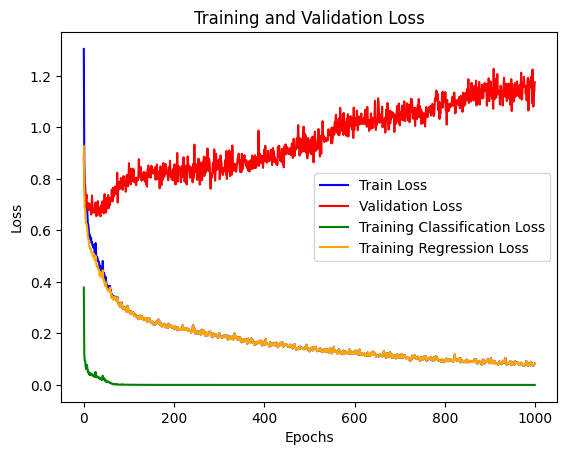

In [17]:
# Plot training/validation loss
plt.figure()
plt.plot(train_losses, label="Train Loss", color="blue")
plt.plot(val_losses, label="Validation Loss", color="red")
plt.plot(train_C_losses, label='Training Classification Loss', color='green')
plt.plot(train_R_losses, label='Training Regression Loss', color='orange')

#plt.plot(val_C_accuracies, label="Validation Classification Accuracy", color="green")
#plt.plot(val_R_accuracies, label="Validation Regression Accuracy", color='orange')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()